# EMMET: marker positivity by organ, AI versus Otsu

One heatmap table per project, with **markers as rows** and **organs as columns**.
Each entry displays the observed positive-cell proportion:

$$P_{m,r}=\frac{N_{\mathrm{positive},m,r}}{N_{\mathrm{classified\ cells},r}}.$$

The numbers are actual positive-cell percentages P. Background colors show **row-normalized regional positivity**, calculated separately for each marker on a scale shared by both methods:

$$Q^{(k)}_{m,r}=\frac{P^{(k)}_{m,r}}{\max_{j\in\{\mathrm{AI},\mathrm{Otsu}\},\,s:\,E_{m,s}\in\{H,L\}} P^{(j)}_{m,s}}\quad\text{for }E_{m,r}\in\{H,L\},$$

where k is the method.

The lowest color means 0 positive cells (Q = 0%) and the highest color marks the highest
displayed value in the row across both methods (Q = 100%). Colors can therefore be compared
between the Otsu and AI-based tables, and only one of them reaches the highest color in a given
row unless they tie. **U entries are blank:** no percentage, no color, and no
effect on the normalization. An all-zero marker stays at the lowest color; an empty H/L region
is marked N/A. Colors show relative localization, not absolute abundance, and cannot be compared
between rows: a row's highest value always gets the highest color, however small it is, so read
the actual P alongside the color.

**The Brain column is evaluated down the column**, because GLUT1 is included to show that
it is the positive marker in the brain. Each displayed Brain entry is split by a diagonal:
the top-left triangle keeps the row-normalized color Q, and the bottom-right triangle shows
the **column-normalized** value on a separate red scale:

$$C^{(k)}_{m,\mathrm{brain}}=\frac{P^{(k)}_{m,\mathrm{brain}}}{\max_{j\in\{\mathrm{AI},\mathrm{Otsu}\},\,n:\,E_{n,\mathrm{brain}}\in\{H,L\}} P^{(j)}_{n,\mathrm{brain}}}\quad\text{for }E_{m,\mathrm{brain}}\in\{H,L\}.$$

Here too, the lowest color means 0 positive cells and the highest color marks the highest
displayed value in the column across both methods.

Cells are assigned by their centroid in **StarDist_Expand for both projects**.
Calls are read directly from the project's positivity lookup tables: 1 = negative, 2 = positive.
Missing marker lookup tables raise an error. Cells without a binary call for any of the
six selected markers are excluded from all marker denominators and reported separately;
they are not interpreted as negative. Thus every marker row uses the same eligible cells.
If organ polygons overlap, cells in multiple organs are excluded and their number is reported.
Cells outside the selected organs are also excluded. H/L/U expectations affect display and color normalization only; raw P remains available for all organs.

The stored AI calls reference StarDist and the Otsu calls reference StarDist_Expand;
positivity calls are indexed by cell ID. This notebook uses **StarDist_Expand** in both
projects for consistent cell centroids. Denominators can still differ if a project has
unclassified cells; these exclusions are displayed below.
No CSVs or separate figures are written.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Polygon, Rectangle
from matplotlib.patheffects import withStroke
from IPython.display import display
from shapely import intersects_xy, union_all
import geopandas as gpd

REPO_ROOT = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "opal_studio" / "project_io.py").is_file()
)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
from opal_studio import project_io

PROJECTS = {
    "AI": REPO_ROOT / "Projects" / "EMMET_AI.zarr",
    "Otsu": REPO_ROOT / "Projects" / "EMMET_Otsu.zarr",
}
MARKERS = {
    "pro-SPC": "144Nd_pro-SPC",
    "NPHS2": "167Er_NPHS2",
    "EPCAM": "176Yb_EPCAM",
    "DESMIN": "174Yb_DESMIN",
    "SOX9": "147Sm_SOX9",
    "GLUT1": "166Er_GLUT1",
}
REGIONS = ["kidney", "lung", "heart", "liver", "brain", "midgut", "bone/cartilage"]
SEGMENTATION = "StarDist_Expand"

# H/L/U expectations from the supplied embryo-marker table, in REGIONS order. Changed to L there:
# SOX9 in heart and liver (only valve and bile duct precursors), DESMIN in liver and brain
# (only stellate cells and pericytes).
EXPECTATIONS = pd.DataFrame.from_dict({
    "pro-SPC": "L H L L L L L".split(),
    "NPHS2": "H L L L L L L".split(),
    "EPCAM": "H H L U L H L".split(),
    "DESMIN": "U U H L L H U".split(),
    "SOX9": "U H L L U H H".split(),
    "GLUT1": "U U U H H U U".split(),
}, orient="index", columns=REGIONS).reindex(MARKERS)


In [2]:
def element_index(store, directory):
    """Map original element names to their on-disk directories."""
    elements = {}
    for meta_path in (store / directory).glob("*/zarr.json"):
        if directory == "opal_aux":
            attrs = json.loads(meta_path.read_text())["attributes"]
            key = attrs.get("opal_key", meta_path.parent.name)
        else:
            key = project_io._read_element_key(meta_path, meta_path.parent.name)
        elements[key] = meta_path.parent
    return elements


def cell_centroids(labels, block_rows=128):
    """Accumulate centroids in row blocks to limit memory use on this large image."""
    if labels.ndim != 2 or labels.dtype.kind not in "iu" or labels.min() < 0:
        raise ValueError("Expected a 2D nonnegative integer segmentation")
    n_labels = int(labels.max()) + 1
    sizes = np.zeros(n_labels, dtype=np.int64)
    sum_x = np.zeros(n_labels, dtype=float)
    sum_y = np.zeros(n_labels, dtype=float)
    height, width = labels.shape
    for start in range(0, height, block_rows):
        stop = min(start + block_rows, height)
        block = labels[start:stop].ravel()
        sizes += np.bincount(block, minlength=n_labels)
        sum_x += np.bincount(block, weights=np.tile(np.arange(width, dtype=float), stop-start),
                             minlength=n_labels)
        sum_y += np.bincount(block, weights=np.repeat(np.arange(start, stop, dtype=float), width),
                             minlength=n_labels)
    ids = np.flatnonzero(sizes)
    ids = ids[ids > 0]
    if not ids.size:
        raise ValueError("Segmentation has no cells")
    return ids, sum_x[ids] / sizes[ids], sum_y[ids] / sizes[ids]


def project_proportions(store):
    """Count stored marker-positive cells within unambiguous organ regions."""
    session = json.loads((store / "zarr.json").read_text())["attributes"]["opal_studio"]["session"]
    channels = {c["source_marker"]: c for c in session["channels"]
                if c.get("kind") == "cell_mask"}
    selected = {name: channels[source] for name, source in MARKERS.items()}
    references = {tuple(c["data_ref"]) for c in selected.values()}
    if len(references) != 1:
        raise ValueError(f"{store.name}: selected markers reference different segmentations")
    directory, stored_segmentation = references.pop()
    if directory != "labels":
        raise ValueError(f"{store.name}: expected a labels segmentation")
    label_path = element_index(store, "labels")[SEGMENTATION]
    labels = project_io._read_v3_array(label_path / "0")
    if labels.ndim == 3 and labels.shape[0] == 1:
        labels = labels[0]
    ids, cx, cy = cell_centroids(labels)
    del labels

    shapes = element_index(store, "shapes")
    inside = np.zeros((len(REGIONS), len(ids)), dtype=bool)
    for i, region in enumerate(REGIONS):
        geometry = gpd.read_parquet(shapes[region] / "shapes.parquet").geometry
        valid = geometry[geometry.notna() & ~geometry.is_empty]
        if valid.empty or not valid.is_valid.all():
            raise ValueError(f"{store.name}: missing or invalid polygons for {region}")
        inside[i] = intersects_xy(union_all(valid.to_numpy()), cx, cy)
    memberships = inside.sum(axis=0)
    overlapping = memberships > 1
    inside[:, overlapping] = False
    aux = element_index(store, "opal_aux")
    calls_by_marker = {}
    eligible = np.ones(len(ids), dtype=bool)
    for marker, channel in selected.items():
        lut = project_io._read_v3_array(aux[channel["pos_lut_key"]]).ravel()
        if ids.max() >= lut.size:
            raise ValueError(f"{store.name}: {marker} lookup table is too short")
        calls = lut[ids]
        if not np.isin(calls, [0, 1, 2]).all():
            raise ValueError(f"{store.name}: unexpected positivity codes for {marker}")
        eligible &= np.isin(calls, [1, 2])
        calls_by_marker[marker] = calls
    unclassified = pd.Series((inside & ~eligible).sum(axis=1), index=REGIONS, dtype=int)
    inside &= eligible
    used = inside.any(axis=0)
    totals = pd.Series(inside.sum(axis=1), index=REGIONS, name="classified cells", dtype=int)
    counts = pd.DataFrame(0, index=list(MARKERS), columns=REGIONS, dtype=int)
    for marker, calls in calls_by_marker.items():
        counts.loc[marker] = (inside & (calls == 2)).sum(axis=1)
    proportions = counts.div(totals.replace(0, np.nan), axis="columns")
    info = {"segmentation": SEGMENTATION, "stored call segmentation": stored_segmentation, "segmented cells": len(ids),
            "cells in selected organs": int(used.sum()),
            "outside organs": int((memberships == 0).sum()),
            "overlapping organs (excluded)": int(overlapping.sum()),
            "unclassified in organs (excluded)": int(unclassified.sum())}
    return {"P": proportions, "positive_counts": counts, "region_totals": totals,
            "unclassified_counts": unclassified, "info": info}

## Read counts and denominators

The regional denominator counts and excluded unclassified-cell counts are displayed first. `analyses["AI"]["P"]` and
`analyses["Otsu"]["P"]` hold the raw proportions; `positive_counts` holds their numerators.

In [3]:
analyses = {}
for method, store in PROJECTS.items():
    print(f"Reading {store.name}...", flush=True)
    analyses[method] = project_proportions(store)
    print(f"Finished {method}.", flush=True)
display(pd.DataFrame({method: result["info"] for method, result in analyses.items()}).T)
denominators = pd.DataFrame({
    (method, label): result[key]
    for method, result in analyses.items()
    for label, key in [("classified cells", "region_totals"),
                       ("unclassified (excluded)", "unclassified_counts")]
}).T
denominators.index.names = ["method", "cell population"]
display(denominators)

Reading EMMET_AI.zarr...


Finished AI.


Reading EMMET_Otsu.zarr...


Finished Otsu.


,segmentation,stored call segmentation,segmented cells,cells in selected organs,outside organs,overlapping organs (excluded),unclassified in organs (excluded)
AI,StarDist_Expand,StarDist_Expand,866792,298458,568126,0,208
Otsu,StarDist_Expand,StarDist_Expand,866792,298458,568126,0,208


kidney   lung  heart   liver  brain  midgut  \
method cell population                                                        
AI     classified cells          22265  36721  19065  133905  46483   36089   
       unclassified (excluded)      13     32     15      76     15      42   
Otsu   classified cells          22265  36721  19065  133905  46483   36089   
       unclassified (excluded)      13     32     15      76     15      42   

                                bone/cartilage  
method cell population                          
AI     classified cells                   3930  
       unclassified (excluded)              15  
Otsu   classified cells                   3930  
       unclassified (excluded)              15

## Marker-by-region tables

**Numbers show actual positive-cell percentages P. Colors run from 0 positive cells (lowest
color) to the highest displayed value in the row across both methods (highest color), so
colors can be compared between the Otsu and AI-based tables. U entries are completely blank and do not affect the colors.**

The mask follows `EXPECTATIONS` above. H and L entries remain visible, including low
values and zeros. All raw proportions, including U regions, remain in `analyses`.
Read actual percentages alongside colors: this normalization can amplify small signals,
and the colors cannot be compared between rows.

**In the Brain column, the top-left triangle is the row-normalized color and the bottom-right
triangle is the column-normalized color**, on the red scale, where the highest color marks the
highest displayed value in the column across both methods. The number is the same actual P for both triangles.

The figure shows three tables, from top to bottom: expected, Otsu, AI-based. Regional cell counts are in the
denominator table above. The first table shows the expectations themselves, without numbers:
the highest color for H, the lowest color for L, and blank for U. Its two colorbars show the
low and high ends of the row (blue) and column (red) scales. A red border marks the Brain
column, evaluated down the column, and each of the top five marker rows has its own blue
border, because each of these is evaluated across its row.

**The number to the right of each of the top five rows and below the Brain column shows how
well that row or column matches the expected table.** It is the average color value of the H
entries minus the average color value of the L entries, using the scale shared by both methods.
100% is a perfect match with the expected table: every H entry has the highest color and every
L entry has 0 positive cells. 0% means H and L have the same color, and a negative value means L
is higher than H. Because the highest color is set by whichever method has the higher value,
the score favors the method that calls more cells positive, as long as its L entries stay low.

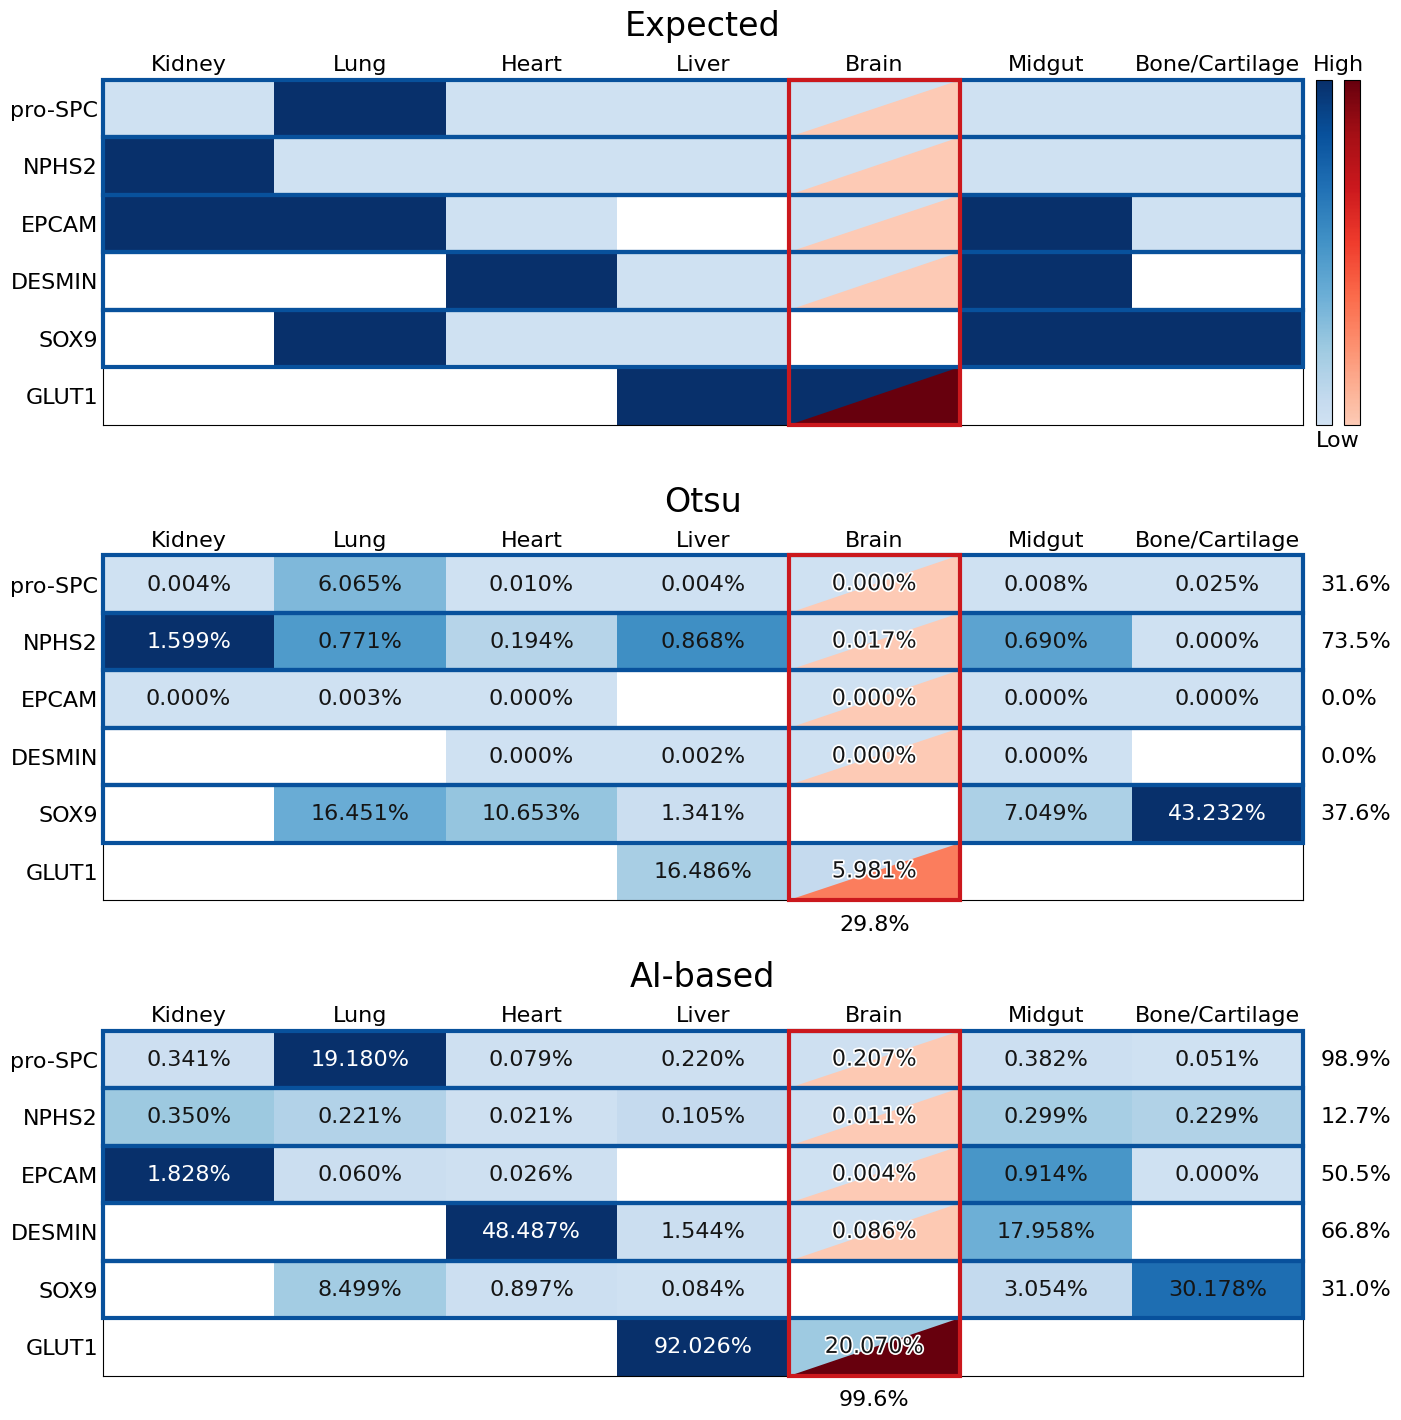

In [4]:
SPLIT_REGION = "brain"
BOXED_ROWS = 5
N_TABLES = 3
TEXT_SIZE, TITLE_SIZE = 16, 24
TITLES = {"Otsu": "Otsu", "AI": "AI-based"}
ROW_CMAP, COLUMN_CMAP = (
    # Skip the near-white start of each scale so that low values still read as blue or red.
    LinearSegmentedColormap.from_list(name, plt.get_cmap(name)(np.linspace(0.2, 1, 256)))
    for name in ("Blues", "Reds")
)


def row_colors(tables):
    """Divide each marker row by its maximum across all projects; preserve zeros and NaNs."""
    row_max = pd.concat([p.max(axis=1) for p in tables.values()], axis=1).max(axis=1)
    return {method: p.div(row_max.where(row_max > 0, 1), axis="index")
            for method, p in tables.items()}


def column_colors(tables):
    """Divide each organ column by its maximum across all projects; preserve zeros and NaNs."""
    column_max = pd.concat([p.max(axis=0) for p in tables.values()], axis=1).max(axis=1)
    return {method: p.div(column_max.where(column_max > 0, 1), axis="columns")
            for method, p in tables.items()}


def match_score(values, expected):
    """Mean color value of the H entries minus that of the L entries."""
    return values[expected == "H"].mean() - values[expected == "L"].mean()


def draw_table(fig, slot, title, colors, column_shares, numbers=None, scale_bars=False):
    """Draw one marker-by-organ table; `numbers` holds the proportions to print, if any."""
    cmap = ROW_CMAP.copy()
    cmap.set_bad("white")
    bottom, height = (N_TABLES - 1 - slot + 0.08) / N_TABLES, 0.725 / N_TABLES
    ax = fig.add_axes([0.062, bottom, 0.822, height])
    ax.imshow(np.ma.masked_invalid(colors.to_numpy()), cmap=cmap,
                      vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(REGIONS)), [r.title() for r in REGIONS], fontsize=TEXT_SIZE)
    ax.xaxis.tick_top()
    ax.set_yticks(range(len(MARKERS)), list(MARKERS), fontsize=TEXT_SIZE)
    split = REGIONS.index(SPLIT_REGION)
    for i in range(len(MARKERS)):
        for j in range(len(REGIONS)):
            if EXPECTATIONS.iat[i, j] == "U":
                continue
            if j == split and pd.notna(column_shares.iat[i, j]):
                # The bottom-right triangle covers the row color; a number sits on both.
                ax.add_patch(Polygon([(j+0.5, i-0.5), (j+0.5, i+0.5), (j-0.5, i+0.5)],
                                     facecolor=COLUMN_CMAP(column_shares.iat[i, j]),
                                     edgecolor="none"))
            if numbers is None:
                continue
            value, shade = numbers.iat[i, j], colors.iat[i, j]
            text = "N/A" if pd.isna(value) else f"{value:.3%}"
            if j == split:
                ax.text(j, i, text, ha="center", va="center", fontsize=TEXT_SIZE, color="#151515",
                        path_effects=[withStroke(linewidth=2.5, foreground="white")])
            else:
                ax.text(j, i, text, ha="center", va="center", fontsize=TEXT_SIZE,
                        color="white" if pd.notna(shade) and shade > 0.7 else "#151515")
    ax.tick_params(length=0)
    ax.set_title(title, fontsize=TITLE_SIZE, pad=14)
    # Drawn over the axes frame, so they are not clipped at the table's outer edge.
    for i in range(BOXED_ROWS):
        ax.add_patch(Rectangle((-0.5, i-0.5), len(REGIONS), 1, fill=False,
                               edgecolor="#08519c", linewidth=3, clip_on=False, zorder=4))
    ax.add_patch(Rectangle((split-0.5, -0.5), 1, len(MARKERS), fill=False,
                           edgecolor="#cb181d", linewidth=3, clip_on=False, zorder=5))
    if numbers is not None:
        for i in range(BOXED_ROWS):
            # Rows without both H and L entries have no score.
            # Rounding first, then adding 0.0, avoids printing -0.0%.
            score = round(match_score(colors.iloc[i], EXPECTATIONS.iloc[i]), 3) + 0.0
            ax.text(len(REGIONS)-0.4, i, "–" if pd.isna(score) else f"{score:.1%}",
                    ha="left", va="center", fontsize=TEXT_SIZE)
        ax.text(split, len(MARKERS)-0.25,
                f"{match_score(column_shares.iloc[:, split], EXPECTATIONS.iloc[:, split]):.1%}",
                ha="center", va="top", fontsize=TEXT_SIZE)
    if scale_bars:
        for scale, left in [(ROW_CMAP, 0.893), (COLUMN_CMAP, 0.912)]:
            bar = fig.colorbar(ScalarMappable(Normalize(0, 1), scale),
                               cax=fig.add_axes([left, bottom, 0.011, height]))
            bar.set_ticks([])
        fig.text(0.908, bottom+height+0.004, "High", ha="center", va="bottom", fontsize=TEXT_SIZE)
        fig.text(0.908, bottom-0.004, "Low", ha="center", va="top", fontsize=TEXT_SIZE)


# Mask U before normalization, preserving raw P in analyses.
proportions = {
    method: result["P"].where(EXPECTATIONS.ne("U"))
    for method, result in analyses.items()
}
normalized = row_colors(proportions)
column_normalized = column_colors(proportions)
levels = EXPECTATIONS.apply(lambda column: column.map({"H": 1.0, "L": 0.0}))
# The table height grows with the number of markers.
fig = plt.figure(figsize=(14.6, 3.17 * len(MARKERS) / 4 * N_TABLES))
draw_table(fig, 0, "Expected", levels, levels, scale_bars=True)
for slot, method in enumerate(TITLES, start=1):
    draw_table(fig, slot, TITLES[method], normalized[method], column_normalized[method],
               numbers=analyses[method]["P"])
plt.show()